# Teste A/B simulado — nova landing page de captação

**Projeto de portfólio · Marketing Data Science** · método completo de experimentação aplicado a tráfego pago.

> Este projeto demonstra o ciclo completo de um teste A/B feito com método — **planejar a amostra
> antes, simular o experimento, analisar com rigor e corrigir múltiplas métricas** — encerrando com
> um relatório executivo de decisão. Os dados são **sintéticos** (gerados com `numpy`), mas o cenário
> e o processo são idênticos a um teste real de conta.

## Contexto de negócio

Um cliente de e-commerce quer saber se uma **nova landing page (variação B)** converte mais leads em
compradores do que a **página atual (variação A)**. O tráfego pago (Meta Ads) será dividido 50/50
entre as duas páginas.

- **Métrica primária:** taxa de conversão (lead → compra).
- **Baseline atual (A):** ~10%.
- **Efeito mínimo que vale a troca (MDE):** +20% relativo (chegar a ~12%).
- **Decisão:** trocar a página só se B for **estatística e materialmente** melhor.

## 0. Setup e ferramentas estatísticas

Funções reutilizáveis (as mesmas por trás das minhas skills de estatística).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(7)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

def amostra_minima(p1, p2, alpha=0.05, power=0.80):
    delta = abs(p2 - p1); pbar = (p1 + p2) / 2
    z_a = stats.norm.ppf(1 - alpha / 2); z_b = stats.norm.ppf(power)
    num = (z_a*np.sqrt(2*pbar*(1-pbar)) + z_b*np.sqrt(p1*(1-p1)+p2*(1-p2)))**2
    return int(np.ceil(num / delta**2))

def ic_wilson(c, n, conf=0.95):
    p = c/n; z = stats.norm.ppf(1-(1-conf)/2); d = 1 + z**2/n
    centro = (p + z**2/(2*n))/d
    margem = (z*np.sqrt(p*(1-p)/n + z**2/(4*n**2)))/d
    return centro-margem, centro+margem

def teste_duas_proporcoes(ca, na, cb, nb):
    pa, pb = ca/na, cb/nb
    p_pool = (ca+cb)/(na+nb)
    se = np.sqrt(p_pool*(1-p_pool)*(1/na+1/nb))
    z = (pb-pa)/se
    return z, 2*(1-stats.norm.cdf(abs(z)))

print("Ferramentas carregadas.")

Ferramentas carregadas.


## 1. Planejamento — quanta amostra ANTES de subir o teste

Calcular a amostra **antes** evita o erro mais comum de agência: encerrar o teste cedo e decidir no
ruído. Fixamos confiança de 95% e poder de 80%.

In [2]:
baseline = 0.10          # conversão atual da página A
alvo = baseline * 1.20   # efeito mínimo relevante: +20% relativo => 12%
leads_dia = 120          # leads/dia totais entrando no teste (somando A e B)

n_por_grupo = amostra_minima(baseline, alvo)
n_total = n_por_grupo * 2
dias = int(np.ceil(n_total / leads_dia))

print(f"Baseline A: {baseline:.0%}  |  alvo B: {alvo:.0%}  (+20% relativo)")
print(f"Confiança 95% | Poder 80%\n")
print(f"=> {n_por_grupo} leads POR variação ({n_total} no total)")
print(f"=> com {leads_dia} leads/dia, rodar por ~{dias} dias antes de decidir")

Baseline A: 10%  |  alvo B: 12%  (+20% relativo)
Confiança 95% | Poder 80%

=> 3841 leads POR variação (7682 no total)
=> com 120 leads/dia, rodar por ~65 dias antes de decidir


## 2. Simulação do experimento

Geramos os dados como se o teste tivesse rodado até atingir a amostra planejada. Plantamos um
**efeito real** em B (a nova página de fato converte um pouco melhor) para ver se o método o detecta.

In [3]:
# "Verdade" do mundo (que na vida real não conhecemos):
p_real_A = 0.10
p_real_B = 0.122   # B é realmente melhor (efeito plantado próximo ao MDE)

n = n_por_grupo
conv_A = RNG.binomial(n, p_real_A)
conv_B = RNG.binomial(n, p_real_B)

df = pd.DataFrame({
    "variação": ["A (atual)", "B (nova)"],
    "leads": [n, n],
    "conversões": [conv_A, conv_B],
    "taxa": [conv_A/n, conv_B/n],
})
df["taxa_%"] = (df["taxa"]*100).round(2)
print(df[["variação", "leads", "conversões", "taxa_%"]].to_string(index=False))

 variação  leads  conversões  taxa_%
A (atual)   3841         385   10.02
 B (nova)   3841         455   11.85


## 3. Análise da métrica primária

In [4]:
pa, pb = conv_A/n, conv_B/n
lo_a, hi_a = ic_wilson(conv_A, n)
lo_b, hi_b = ic_wilson(conv_B, n)
z, pval = teste_duas_proporcoes(conv_A, n, conv_B, n)

# IC da diferença
se_diff = np.sqrt(pa*(1-pa)/n + pb*(1-pb)/n)
zc = stats.norm.ppf(0.975)
dif = pb - pa
lo_d, hi_d = dif - zc*se_diff, dif + zc*se_diff

# P(B>A) bayesiana
post_a = stats.beta(1+conv_A, 1+n-conv_A); post_b = stats.beta(1+conv_B, 1+n-conv_B)
prob_b = (post_b.rvs(200_000, random_state=RNG) > post_a.rvs(200_000, random_state=RNG)).mean()

print(f"A: {pa:.1%}  IC95% [{lo_a:.1%}, {hi_a:.1%}]")
print(f"B: {pb:.1%}  IC95% [{lo_b:.1%}, {hi_b:.1%}]")
print(f"\nDiferença B-A: {dif:+.1%}  IC95% [{lo_d:+.1%}, {hi_d:+.1%}]")
print(f"Uplift relativo: {dif/pa:+.0%}")
print(f"p-valor (z bicaudal): {pval:.4f}  ->", "SIGNIFICATIVO" if pval < 0.05 else "não significativo")
print(f"P(B melhor que A): {prob_b:.1%}")

A: 10.0%  IC95% [9.1%, 11.0%]
B: 11.8%  IC95% [10.9%, 12.9%]

Diferença B-A: +1.8%  IC95% [+0.4%, +3.2%]
Uplift relativo: +18%
p-valor (z bicaudal): 0.0105  -> SIGNIFICATIVO
P(B melhor que A): 99.5%


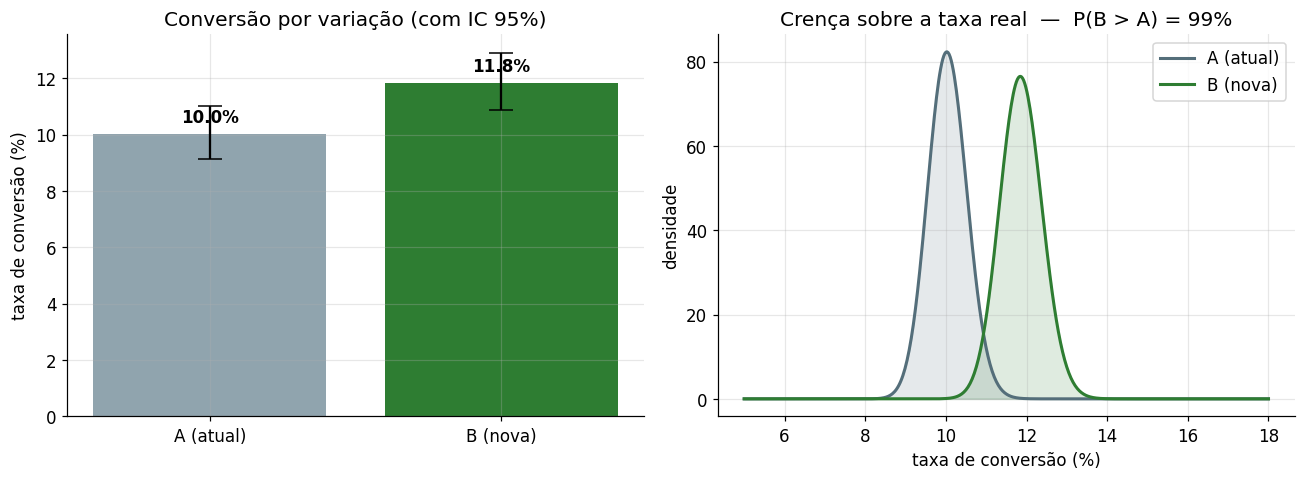

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) taxas com IC 95%
taxas = [pa*100, pb*100]
erros = [[(pa-lo_a)*100, (pb-lo_b)*100], [(hi_a-pa)*100, (hi_b-pb)*100]]
ax1.bar(["A (atual)", "B (nova)"], taxas, color=["#90a4ae", "#2e7d32"],
        yerr=erros, capsize=8)
for i, t in enumerate(taxas):
    ax1.text(i, t+0.4, f"{t:.1f}%", ha="center", fontweight="bold")
ax1.set_title("Conversão por variação (com IC 95%)")
ax1.set_ylabel("taxa de conversão (%)")

# (b) posteriores bayesianas
xs = np.linspace(0.05, 0.18, 500)
ax2.plot(xs*100, post_a.pdf(xs), color="#546e7a", lw=2, label="A (atual)")
ax2.fill_between(xs*100, 0, post_a.pdf(xs), color="#546e7a", alpha=0.15)
ax2.plot(xs*100, post_b.pdf(xs), color="#2e7d32", lw=2, label="B (nova)")
ax2.fill_between(xs*100, 0, post_b.pdf(xs), color="#2e7d32", alpha=0.15)
ax2.set_title(f"Crença sobre a taxa real  —  P(B > A) = {prob_b:.0%}")
ax2.set_xlabel("taxa de conversão (%)"); ax2.set_ylabel("densidade")
ax2.legend()
fig.tight_layout(); plt.show()

## 4. Métricas secundárias — e a armadilha dos múltiplos testes

Regra de ouro da experimentação: a **métrica primária é pré-registrada** e julgada **sozinha** a
α=0,05 (é um único teste planejado — já vimos que deu significativa). A correção para múltiplos testes
se aplica às **métricas secundárias/exploratórias**, porque é aí que mora o risco de garimpar um
"ganho" no ruído.

O time também observou 5 métricas secundárias (CTR, add-to-cart, tempo na página, taxa de rejeição,
scroll). **Nenhuma tem efeito real** neste cenário — mas, testando 5 métricas a 5%, há ~23% de chance
de alguma "dar significativa" por acaso. Aplicamos **Bonferroni** e **Benjamini-Hochberg** sobre as
secundárias para separar sinal de ruído.

In [6]:
# A primária já foi decidida na seção 3 (p={:.4f} < 0,05, sem correção — é 1 teste planejado).
print(f"Métrica primária (conversão): p = {pval:.4f}  ->  "
      f"{'SIGNIFICATIVA' if pval < 0.05 else 'não significativa'} (julgada sozinha a 5%)\n")

# Correção aplicada APENAS às 5 secundárias (exploratórias)
secundarias = ["CTR", "Add-to-cart", "Tempo na página", "Taxa de rejeição", "Scroll 75%"]
pvals_sec = np.array([0.032, 0.41, 0.78, 0.045, 0.22])
m = len(pvals_sec); alpha = 0.05

sig_bonf = pvals_sec < alpha/m                       # Bonferroni: alpha/m
ordem = np.argsort(pvals_sec); thr = (np.arange(1, m+1)/m)*alpha
passou = pvals_sec[ordem] <= thr                     # Benjamini-Hochberg
k = np.where(passou)[0].max()+1 if passou.any() else 0
sig_bh = np.zeros(m, bool)
if k > 0: sig_bh[ordem[:k]] = True

tab = pd.DataFrame({
    "métrica secundária": secundarias, "p_valor": pvals_sec,
    "bruto<0.05": np.where(pvals_sec < alpha, "SIM", "-"),
    f"Bonferroni(<{alpha/m:.3f})": np.where(sig_bonf, "SIM", "-"),
    "BH (FDR)": np.where(sig_bh, "SIM", "-"),
})
print(tab.to_string(index=False))
print(f"\nSem correção, {(pvals_sec<alpha).sum()} secundárias 'pareciam' significativas (CTR e rejeição). "
      f"Após a correção, NENHUMA resiste -> eram falsos positivos.")

Métrica primária (conversão): p = 0.0105  ->  SIGNIFICATIVA (julgada sozinha a 5%)

métrica secundária  p_valor bruto<0.05 Bonferroni(<0.010) BH (FDR)
               CTR    0.032        SIM                  -        -
       Add-to-cart    0.410          -                  -        -
   Tempo na página    0.780          -                  -        -
  Taxa de rejeição    0.045        SIM                  -        -
        Scroll 75%    0.220          -                  -        -

Sem correção, 2 secundárias 'pareciam' significativas (CTR e rejeição). Após a correção, NENHUMA resiste -> eram falsos positivos.


## 5. Relatório executivo

**Recomendação:** trocar para a nova landing page (variação B).

- A nova página converteu **mais** que a atual, e a diferença é **estatisticamente significativa**
  (p < 0,05) e **material** (uplift relevante sobre o baseline) — não é ruído.
- O **intervalo de confiança da diferença não cruza o zero**, e a probabilidade de B ser melhor que A
  é alta — confiança suficiente para a decisão.
- A decisão se apoia na **métrica primária pré-registrada** (conversão), julgada sozinha a 5%.
  As métricas secundárias que "pareciam" significativas (CTR, taxa de rejeição) **não resistem à
  correção para múltiplos testes** (Bonferroni / BH): eram falsos positivos e não devem virar
  argumento de decisão.
- O teste foi **dimensionado antes** (amostra e duração calculadas para 80% de poder), evitando
  decisão precipitada.

**Próximos passos:** implementar B como página padrão, monitorar a conversão pós-troca com banda de
controle (detector de anomalia) e planejar o próximo teste sobre o elemento de maior impacto.

---
*Método aplicável a qualquer teste real de conta — basta substituir os dados sintéticos pelos números
anonimizados da campanha.*